# Project 3 – Depot Loading Turnaround Time (TAT) Analysis

**Source:** `data/Project3_EmployeeTurnAround.xlsx` (we only read it; we never change it).

**What the workbook really contains:** despite the file name, this is **not** employee turnover data.
It is a fuel-depot **loading log** from *Accra Plains Depot*. Each row is one tanker truck
(a **BRV**, Bulk Road Vehicle) that came in to load fuel. The log records:

| Column | Meaning |
|---|---|
| BOST/ OMC | Who the load is for: **BOST** (state strategic stock) or an **OMC** (Oil Marketing Company) |
| BRV # | Truck registration number |
| BDC | Bulk Distribution Company that owns the product |
| TRANSPORTER | Haulage company for BOST loads; for OMC loads it holds the **OMC customer name** |
| PRODUCT | **AGO** = diesel, **PMS** = petrol |
| CAPACITY | Truck size in litres |
| TIME IN / TIME OUT | When the truck entered and left the depot |
| TAT | Turnaround time = TIME OUT − TIME IN |
| REMARKS | **Passed** if TAT ≤ 1:45 (the target), **Failed** if longer, **No Remarks** if the truck is under 45,000 L (not assessed) |
| MEAS | 15-minute TAT band (x1 = under 1 hour … x10 = 3 hours or more) |
| CR | Challenge Register: the code for *why* a failed truck was late |

The sheets are three daily reports: **03 May 2023** (90 trucks), **04 May 2023** (90 trucks) and **31 May 2025** (218 trucks).
Note: the 04 May 2023 rows are identical to the 03 May rows (same trucks, same times). We keep 04 May as its own day, as the data owner confirmed, and flag the repeat as a data-quality issue.

### Business problems we will answer
1. **Overall TAT compliance:** what share of trucks meet the 1:45 target, and did that change from 2023 to 2025?
2. **KPI coverage:** how many trucks are left out of the KPI, and how do small trucks perform?
3. **How late are late trucks?** What does the TAT distribution look like in 15-minute bands?
4. **Product:** do diesel (AGO) and petrol (PMS) loads perform differently?
5. **Customer channel:** BOST compared with OMC loads.
6. **BDC performance:** which product owners have the slowest loads?
7. **Hauliers and OMC customers:** who are the repeat late trucks?
8. **Time of arrival:** is there a congestion peak?
9. **Root causes:** what does the Challenge Register say, and can we trust it?
10. **Cost of delay:** how many truck-hours are lost above target?

In [1]:
# Import the libraries we need
import pandas as pd
import matplotlib.pyplot as plt

# Show all columns when we print a table
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Path to the source workbook (read-only, we never save over it)
file = "../data/Project3_EmployeeTurnAround.xlsx"

## 1. Understand the workbook

In [2]:
# List the sheets. Note the trailing spaces in the names, so we pick sheets by position instead.
sheets = pd.ExcelFile(file).sheet_names
print(sheets)

['31.05.2025     ', '03.05.2023 ', '04.05.2023']


In [3]:
# The data table starts on row 5 (header=4 means "use the 5th row as column names").
# Columns A:M hold the log; the columns to the right hold the summary tables and charts.
day_2025 = pd.read_excel(file, sheet_name=0, header=4, usecols="A:M")
day_2023 = pd.read_excel(file, sheet_name=1, header=4, usecols="A:M")
day_2023b = pd.read_excel(file, sheet_name=2, header=4, usecols="A:M")   # 04 May 2023

day_2025.head()

,ITEM,BOST/ OMC,BRV #,BDC,TRANSPORTER,PRODUCT,CAPACITY,TIME IN,TIME OUT,TAT,REMARKS,MEAS,CR
0,1.0,BOST,AC 1788-20,BOST (G4O),A-BEK,AGO,54000.0,16:16:00,19:00:00,02:44:00,Failed,x8,DD
1,2.0,BOST,AW 9631-13,BOST (G4O),SADICK,AGO,54000.0,15:46:00,18:10:00,02:24:00,Failed,x7,DD
2,3.0,BOST,AC 1544-19,BOST (G4O),A-BEK,AGO,54000.0,16:14:00,18:05:00,01:51:00,Failed,x5,DD
3,4.0,BOST,GT 8901-17,BOST (G4O),HALFAST,AGO,54000.0,15:45:00,17:30:00,01:45:00,Passed,x4,NaN
4,5.0,BOST,GT 8033-Z,BOST (G4O),SASCO,AGO,49500.0,15:56:00,17:35:00,01:39:00,Passed,x4,NaN


In [4]:
# Each sheet's report date is in cell C2. Read it to label the days.
dates = pd.read_excel(file, sheet_name=None, header=None, usecols="C", nrows=2)
for name, d in dates.items():
    print(repr(name), "->", d.iloc[1, 0])

# 04 May has its own date, but are its rows different from 03 May?
print("04 May rows identical to 03 May rows:", day_2023.equals(day_2023b))

'31.05.2025     ' -> 2025-05-31 00:00:00
'03.05.2023 ' -> 2023-05-03 00:00:00
'04.05.2023' -> 2023-05-04 00:00:00
04 May rows identical to 03 May rows: True


In [5]:
# Each table ends with an Excel "Total" row that has no ITEM number. Look at the last 2 rows.
day_2025.tail(2)

,ITEM,BOST/ OMC,BRV #,BDC,TRANSPORTER,PRODUCT,CAPACITY,TIME IN,TIME OUT,TAT,REMARKS,MEAS,CR
217,218.0,OMC,GS 5192-17,EVERSTONE ENERGY LIMITED,STAR OIL CO. LTD,PMS,13500.0,08:30:00,10:09:00,01:39:00,No Remarks,x4,NaN
218,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01:42:13.486000,NaN,NaN,NaN


## 2. Validate the data

In [6]:
# Drop the Excel total row (ITEM is empty there)
day_2025 = day_2025.dropna(subset=["ITEM"])
day_2023 = day_2023.dropna(subset=["ITEM"])
day_2023b = day_2023b.dropna(subset=["ITEM"])

# Add the report date (from cell C2 of each sheet) and stack the three days into one table
day_2025["DATE"] = "2025-05-31"
day_2023["DATE"] = "2023-05-03"
day_2023b["DATE"] = "2023-05-04"
df = pd.concat([day_2023, day_2023b, day_2025], ignore_index=True)

# Some column names end with a space (e.g. "TAT "), so strip them
df.columns = df.columns.str.strip()

print(df.shape)
df.info()

(398, 14)
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ITEM         398 non-null    float64
 1   BOST/ OMC    398 non-null    str    
 2   BRV #        398 non-null    str    
 3   BDC          398 non-null    str    
 4   TRANSPORTER  398 non-null    str    
 5   PRODUCT      398 non-null    str    
 6   CAPACITY     398 non-null    float64
 7   TIME IN      398 non-null    object 
 8   TIME OUT     398 non-null    object 
 9   TAT          398 non-null    object 
 10  REMARKS      398 non-null    str    
 11  MEAS         398 non-null    str    
 12  CR           106 non-null    str    
 13  DATE         398 non-null    str    
dtypes: float64(2), object(3), str(9)
memory usage: 43.7+ KB


In [7]:
# Blank values per column. CR is only filled in for failed trucks, so blanks there are expected.
df.isna().sum()

ITEM             0
BOST/ OMC        0
BRV #            0
BDC              0
TRANSPORTER      0
PRODUCT          0
CAPACITY         0
TIME IN          0
TIME OUT         0
TAT              0
REMARKS          0
MEAS             0
CR             292
DATE             0
dtype: int64

In [8]:
# Duplicates: same truck number on the same day, or a fully repeated row?
print("Repeated BRV # on the same day:", df.duplicated(subset=["DATE", "BRV #"]).sum())
print("Fully repeated rows (same day):", df.drop(columns="ITEM").duplicated().sum())
print("Rows that repeat another day exactly:", df.drop(columns=["ITEM", "DATE"]).duplicated().sum())

Repeated BRV # on the same day: 0
Fully repeated rows (same day): 0
Rows that repeat another day exactly: 90


In [9]:
# Category columns: look for spelling or spacing problems
for col in ["BOST/ OMC", "PRODUCT", "REMARKS", "CR"]:
    print(df[col].value_counts(dropna=False), "\n")

BOST/ OMC
OMC     321
BOST     77
Name: count, dtype: int64 

PRODUCT
PMS    211
AGO    187
Name: count, dtype: int64 

REMARKS
No Remarks    204
Failed        107
Passed         87
Name: count, dtype: int64 

CR
NaN     292
SLA      49
DD       46
NID      10
RISD      1
Name: count, dtype: int64 



In [10]:
# BDC names: leading/trailing spaces and several spellings of the same company
df["BDC"].value_counts()

BDC
GOENERGY                                       106
BOST (G4O)                                      61
EVERSTONE ENERGY LIMITED                        36
INTERNATIONAL PETROLEUM RESOURCES GH            31
GENYSIS GLOBAL LIMITED                          26
RESTON ENERGY                                   23
OIL CHANNEL                                     21
MARIAJE LINX INVESTMENT LIMITED                 15
ASTRA OIL                                       12
OILTRADE                                        10
NENSER PET                                       9
EVERSTONE ENERGY                                 8
 EAGLE PETROLEUM                                 5
 VIHAMA                                          5
VIHAMA ENERGY LIMITED                            5
EVERSTONE                                        3
FIRM ENERGY                                      3
EBONY OIL                                        3
MISYL ENERGY CO LTD                              3
SAGE DISTRIBUTION LIMITED  

In [11]:
# Truck sizes in litres. 45,000 L is the cut-off for being assessed.
df["CAPACITY"].value_counts().sort_index()

CAPACITY
13250.0      1
13500.0     92
18000.0     10
20000.0      1
22500.0      2
27000.0     49
30000.0      1
31500.0     15
36000.0     29
40000.0      1
40500.0      3
45000.0     28
49500.0      3
50000.0      5
52000.0      1
53500.0      1
54000.0    156
Name: count, dtype: int64

In [12]:
# Turn the clock times into minutes after midnight so we can do maths with them
df["IN_MIN"] = pd.to_timedelta(df["TIME IN"].astype(str)).dt.total_seconds() / 60
df["OUT_MIN"] = pd.to_timedelta(df["TIME OUT"].astype(str)).dt.total_seconds() / 60

# Recalculate TAT ourselves in whole minutes
df["TAT_MIN"] = df["OUT_MIN"] - df["IN_MIN"]

# Check: no negative TAT (would mean an overnight load or a typing error)
print("Negative TAT:", (df["TAT_MIN"] < 0).sum())
print("Shortest / longest TAT (min):", df["TAT_MIN"].min(), "/", df["TAT_MIN"].max())

# Check: does Excel's TAT column agree with our recalculation?
excel_tat = pd.to_timedelta(df["TAT"].astype(str)).dt.total_seconds() / 60
print("Rows where Excel TAT differs:", (excel_tat.round() != df["TAT_MIN"]).sum())

Negative TAT: 0
Shortest / longest TAT (min): 24.0 / 251.0
Rows where Excel TAT differs: 0


In [13]:
# Re-create the Passed / Failed rule: trucks of 45,000 L or more pass if TAT <= 105 minutes (1:45)
df["RESULT"] = "Not assessed"
df.loc[df["CAPACITY"] >= 45000, "RESULT"] = "Passed"
df.loc[(df["CAPACITY"] >= 45000) & (df["TAT_MIN"] > 105), "RESULT"] = "Failed"

# Compare with the workbook's REMARKS column ("No Remarks" = "Not assessed")
pd.crosstab(df["REMARKS"], df["RESULT"])

RESULT,Failed,Not assessed,Passed
REMARKS,,,
Failed,107,0,0
No Remarks,0,204,0
Passed,0,0,87


In [14]:
# Re-create the 15-minute bands. right=False means a band includes its lower edge
# (1:45 exactly goes in the 1:45-2:00 band), which is what the Excel formula intends.
bins = [0, 60, 75, 90, 105, 120, 135, 150, 165, 180, 1000]
labels = ["x1", "x2", "x3", "x4", "x5", "x6", "x7", "x8", "x9", "x10"]
df["MEAS_CHECK"] = pd.cut(df["TAT_MIN"], bins=bins, labels=labels, right=False).astype(str)

# Rows where the workbook put the truck in the wrong band
df[df["MEAS"] != df["MEAS_CHECK"]][["DATE", "ITEM", "BRV #", "TAT", "MEAS", "MEAS_CHECK"]]

,DATE,ITEM,BRV #,TAT,MEAS,MEAS_CHECK
18,2023-05-03,19.0,GG 5062-21,01:45:00,x4,x5
34,2023-05-03,35.0,AW 786-20,01:45:00,x4,x5
108,2023-05-04,19.0,GG 5062-21,01:45:00,x4,x5
124,2023-05-04,35.0,AW 786-20,01:45:00,x4,x5
183,2025-05-31,4.0,GT 8901-17,01:45:00,x4,x5
205,2025-05-31,26.0,GT 8199-18,02:15:00,x6,x7
254,2025-05-31,75.0,GT 7303-22,01:00:00,x1,x2
303,2025-05-31,124.0,GN 6496-22,01:00:00,x1,x2
362,2025-05-31,183.0,GT 4923 -13,01:00:00,x1,x2


In [15]:
# Every failed truck should have a Challenge Register (CR) code. Which do not?
df[(df["RESULT"] == "Failed") & (df["CR"].isna())][["DATE", "ITEM", "BRV #", "PRODUCT", "TAT", "CR"]]

,DATE,ITEM,BRV #,PRODUCT,TAT,CR
347,2025-05-31,168.0,GX 837-21,PMS,01:56:00,NaN


In [16]:
# Does the CR code describe the real cause, or just the product?
pd.crosstab([df["DATE"], df["CR"]], df["PRODUCT"])

PRODUCT          AGO  PMS
DATE       CR            
2023-05-03 NID     5    0
           SLA     0   12
2023-05-04 NID     5    0
           SLA     0   12
2025-05-31 DD     46    0
           RISD    0    1
           SLA     0   25

In [17]:
# The TRANSPORTER column: for BOST loads it holds haulage firms, for OMC loads it holds
# oil marketing companies (GOIL, PUMA ENERGY, STAR OIL ...). Look at the top names for each.
for group in ["BOST", "OMC"]:
    print(group, df[df["BOST/ OMC"] == group]["TRANSPORTER"].str.strip().value_counts().head(5).to_dict())

BOST {'GREEN HAULAGE': 3, 'OIL FAST': 3, 'KTC': 3, 'HIGHGATE': 2, 'A-BEK': 2}


OMC {'GOIL': 98, 'PACIFIC OIL': 25, 'ALLIED OIL COMPANY LIMITED': 22, 'STAR OIL CO. LTD': 16, 'ZEN PETROLEUM': 12}


### Validation summary
* **Three report days.** The sheets cover 03 May 2023, 04 May 2023 and 31 May 2025 (dates from cell C2). **The 04 May rows are identical to the 03 May rows**: all 90 trucks, times and results match. The data owner confirmed 04 May is a separate day, so it is **kept**, but the repeat is **flagged**. The real 04 May log may have been overwritten by a copy of 03 May.
* **Excel total rows** at the bottom of each table are removed.
* **No blank values** in the key columns, **no duplicate trucks within a day** and **no negative TATs**. Excel's TAT matches TIME OUT − TIME IN on every row.
* **Pass/Fail logic is correct** on every row (TAT ≤ 1:45 and capacity ≥ 45,000 L).
* **9 rows are in the wrong 15-minute band (MEAS):** 5 in 2025 and 2 on each 2023 day. All sit exactly on a band edge (1:00, 1:45 or 2:15). Excel time arithmetic gives tiny rounding errors, so `>=1:45` sometimes evaluates as false. The bands are recalculated from whole minutes.
* **1 failed truck has no CR code** (2025, item 168, GX 837-21). It is set to `NR – Not recorded`.
* **The CR codes follow the product, not the cause.** In 2025 every late diesel truck is coded `DD` (dipping/documentation delay) and almost every late petrol truck `SLA` (single loading arm). On the 2023 days every late diesel truck is `NID`. This looks like blanket coding, so the Challenge Register cannot be read as true root causes.
* **The CR code list changed between years** (for example RID→RISD and NID→ND), so the codes are harmonised to one description each.
* **The TRANSPORTER column has two meanings:** a haulier for BOST loads and an OMC customer for OMC loads. It is split into `HAULIER` and `OMC_CUSTOMER`.
* **Name clean-up:** spaces trimmed; 20 BDC values merged (EVERSTONE / EVERSTONE ENERGY / EVERSTONE ENERGY LIMITED, VIHAMA / VIHAMA ENERGY LIMITED, BOST / BOST (G4O), OIL CHANNEL / OIL CHANNEL LIMITED, plus the WOOODFIELDS typo); 18 transporter values merged (OIL FAST/OILFAST, HUSS PET/HUSS PETROLEUM, LIMTED typo and others); 77 truck numbers standardised to `XX 1234-21`.
* **Also noted, not changed:** the 2025 sheet has two cell comments ("Leakage on BRV" on item 61, "No input time recorded" on item 97, so that TIME IN may be estimated). The sheet name says 31.05.2025 but the table is called `May19_2023…`, so it was copied from an older template. The workbook's "Grand Total" average TAT averages the Passed and Failed averages instead of averaging all trucks. A column-N lookup against an external file was removed from the published copy of the workbook.

## 3. Clean the data

In [18]:
# 1) Trim spaces in all text columns
for col in ["BOST/ OMC", "BRV #", "BDC", "TRANSPORTER", "PRODUCT", "CR"]:
    df[col] = df[col].str.strip()

# 2) Standardise truck numbers: remove spaces around the dash, single spaces only
df["BRV #"] = df["BRV #"].str.replace(r"\s*-\s*", "-", regex=True).str.replace(r"\s+", " ", regex=True)

# 3) Merge BDC name variants
bdc_fix = {
    "EVERSTONE": "EVERSTONE ENERGY LIMITED",
    "EVERSTONE ENERGY": "EVERSTONE ENERGY LIMITED",
    "VIHAMA": "VIHAMA ENERGY LIMITED",
    "BOST": "BOST (G4O)",
    "OIL CHANNEL LIMITED": "OIL CHANNEL",
    "WOOODFIELDS ENERGY RESOURCES ENERGY LIMITED": "WOODFIELDS ENERGY RESOURCES LIMITED",
}
df["BDC"] = df["BDC"].replace(bdc_fix)

# 4) Merge transporter / OMC name variants
name_fix = {
    "OILFAST": "OIL FAST",
    "HUSS PET": "HUSS PETROLEUM",
    "GOIL COMPANY LIMITED": "GOIL",
    "RELIANCE OIL": "RELIANCE OIL LIMITED",
    "SO ENERGY GH LIMITED": "SO ENERGY",
    "STRATEGIC ENERGIES LIMTED": "STRATEGIC ENERGIES LIMITED",
}
df["TRANSPORTER"] = df["TRANSPORTER"].replace(name_fix)

# 5) Split TRANSPORTER into its two real meanings
df["HAULIER"] = df["TRANSPORTER"].where(df["BOST/ OMC"] == "BOST")
df["OMC_CUSTOMER"] = df["TRANSPORTER"].where(df["BOST/ OMC"] == "OMC")

# 6) Use the corrected 15-minute band, with readable labels
band_names = {"x1": "1) <1:00", "x2": "2) 1:00-1:15", "x3": "3) 1:15-1:30", "x4": "4) 1:30-1:45",
              "x5": "5) 1:45-2:00", "x6": "6) 2:00-2:15", "x7": "7) 2:15-2:30", "x8": "8) 2:30-2:45",
              "x9": "9) 2:45-3:00", "x10": "10) 3:00+"}
df["TAT_BAND"] = df["MEAS_CHECK"].map(band_names)

# 7) Harmonise Challenge Register codes across the years
cr_names = {
    "SLA": "Single Loading Arm Delay",
    "DD": "Dipping Platform/Documentation Delay",
    "RISD": "Rock Africa Internet/Seal Delay",
    "RID": "Rock Africa Internet/Seal Delay",
    "NID": "NTL (Internet) Delay",
    "ND": "NTL (Internet) Delay",
}
df.loc[(df["RESULT"] == "Failed") & (df["CR"].isna()), "CR"] = "NR"
cr_names["NR"] = "Not recorded"
df["CR_DESC"] = df["CR"].map(cr_names)

# 8) Helpful extra columns
df["ARRIVAL_HOUR"] = (df["IN_MIN"] // 60).astype(int)       # hour the truck came in
df["MINUTES_OVER_TARGET"] = (df["TAT_MIN"] - 105).clip(lower=0).where(df["RESULT"] == "Failed", 0)
df["LITRES_PER_MIN"] = (df["CAPACITY"] / df["TAT_MIN"]).round(1)
df["SIZE_GROUP"] = pd.cut(df["CAPACITY"], bins=[0, 20000, 44999, 100000],
                          labels=["Small (<=20k L)", "Medium (20k-45k L)", "Large (>=45k L)"])

df[["DATE", "BRV #", "BDC", "PRODUCT", "CAPACITY", "TAT_MIN", "RESULT", "TAT_BAND", "CR_DESC"]].head()

,DATE,BRV #,BDC,PRODUCT,CAPACITY,TAT_MIN,RESULT,TAT_BAND,CR_DESC
0,2023-05-03,GE 5199-12,BOST (G4O),AGO,54000.0,83.0,Passed,3) 1:15-1:30,NaN
1,2023-05-03,GN 9286-12,BOST (G4O),AGO,54000.0,86.0,Passed,3) 1:15-1:30,NaN
2,2023-05-03,GN 7534-13,BOST (G4O),AGO,54000.0,92.0,Passed,4) 1:30-1:45,NaN
3,2023-05-03,GW 3759-14,EVERSTONE ENERGY LIMITED,PMS,45000.0,56.0,Passed,1) <1:00,NaN
4,2023-05-03,GT 4727-12,GENYSIS GLOBAL LIMITED,AGO,13500.0,40.0,Not assessed,1) <1:00,NaN


In [19]:
# Keep a tidy, renamed copy of the clean data and save it in the data folder
clean = df.rename(columns={"BOST/ OMC": "CUSTOMER_TYPE", "BRV #": "BRV_NO", "CAPACITY": "CAPACITY_L",
                           "TIME IN": "TIME_IN", "TIME OUT": "TIME_OUT", "CR": "CR_CODE"})
clean = clean[["DATE", "ITEM", "CUSTOMER_TYPE", "BRV_NO", "BDC", "HAULIER", "OMC_CUSTOMER", "PRODUCT",
               "CAPACITY_L", "SIZE_GROUP", "TIME_IN", "TIME_OUT", "ARRIVAL_HOUR", "TAT_MIN", "TAT_BAND",
               "RESULT", "MINUTES_OVER_TARGET", "CR_CODE", "CR_DESC", "LITRES_PER_MIN"]]
clean.to_csv("../data/Project3_LoadingTAT_CleanData_final.csv", index=False)
print(clean.shape)

# Most KPIs use only the assessed trucks (45,000 L and above)
assessed = df[df["RESULT"] != "Not assessed"]
print("Assessed trucks:", len(assessed))

(398, 20)
Assessed trucks: 194


## 4. Analysis
Every chart below is also saved as a PNG in the `images/` folder, so it can be shown in the GitHub README.

In [20]:
import os
os.makedirs("../images", exist_ok=True)   # folder for the chart images

# One simple chart style for the whole notebook
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False,
    "axes.edgecolor": "#8a8985", "axes.titleweight": "bold", "axes.titlesize": 13,
    "font.size": 10, "legend.frameon": False,
})

# Colours: one per job, used the same way in every chart
BLUE, AQUA, ORANGE = "#2a78d6", "#1baf7a", "#eb6834"   # 03 May 2023, 04 May 2023, 31 May 2025
DAY_COLOURS = [BLUE, AQUA, ORANGE]                       # one colour per report day, in date order
GREEN, RED, GREY = "#0ca30c", "#d03b3b", "#b5b4ae"   # Passed, Failed, Not assessed
TARGET = "#52514e"                          # 1:45 target line

### Data quality at a glance

Failed truck with no CR code                      1
Wrong 15-min band fixed                           9
Transporter names merged                         18
BDC names merged                                 20
Truck numbers re-spaced                          77
Rows identical to another day (kept, flagged)    90
dtype: int64

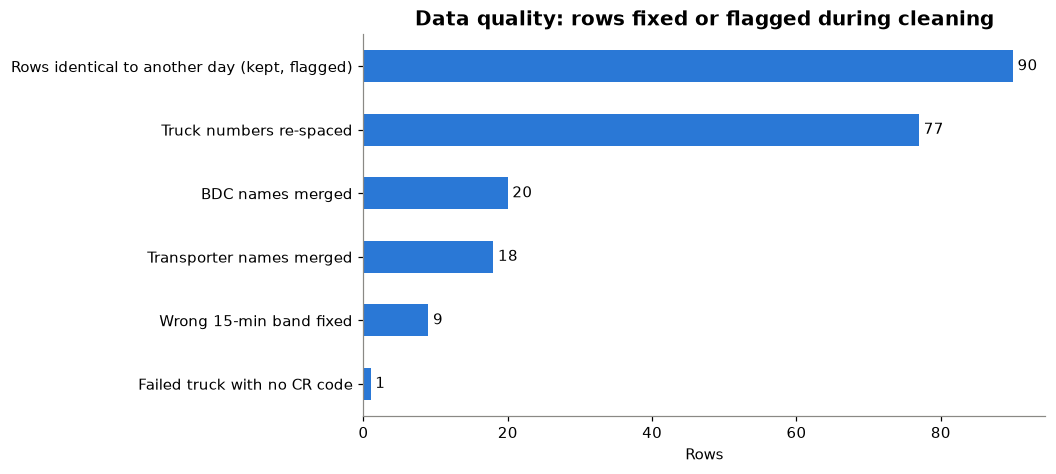

In [21]:
# Count what the cleaning changed (raw values are still in day_2023 / day_2025)
raw = pd.concat([day_2023, day_2023b, day_2025], ignore_index=True)
quality = pd.Series({
    "Rows identical to another day (kept, flagged)": raw.drop(columns=["ITEM", "DATE"]).duplicated().sum(),
    "Truck numbers re-spaced": (raw["BRV #"].values != df["BRV #"].values).sum(),
    "BDC names merged": (raw["BDC"].str.strip().values != df["BDC"].values).sum(),
    "Transporter names merged": (raw["TRANSPORTER"].str.strip().values != df["TRANSPORTER"].values).sum(),
    "Wrong 15-min band fixed": (df["MEAS"] != df["MEAS_CHECK"]).sum(),
    "Failed truck with no CR code": (df["CR"] == "NR").sum(),
}).sort_values()
print(quality)

ax = quality.plot(kind="barh", color=BLUE, title="Data quality: rows fixed or flagged during cleaning")
ax.bar_label(ax.containers[0], padding=3); ax.grid(False); ax.set_xlabel("Rows")
plt.savefig("../images/02_data_quality.png", bbox_inches="tight"); plt.show()

### BP1 – Overall TAT compliance (target 1:45)

In [22]:
# Count Passed and Failed per day, then turn into percentages
bp1 = pd.crosstab(assessed["DATE"], assessed["RESULT"], margins=True)
bp1["Pass rate %"] = (bp1["Passed"] / bp1["All"] * 100).round(1)
print(bp1)

# Average TAT of all trucks and of assessed trucks per day
print(df.groupby("DATE")["TAT_MIN"].mean().round(1))
print(assessed.groupby("DATE")["TAT_MIN"].mean().round(1))

RESULT      Failed  Passed  All  Pass rate %
DATE                                        
2023-05-03      17      23   40         57.5
2023-05-04      17      23   40         57.5
2025-05-31      73      41  114         36.0
All            107      87  194         44.8
DATE
2023-05-03     92.5
2023-05-04     92.5
2025-05-31    102.2
Name: TAT_MIN, dtype: float64
DATE
2023-05-03    101.8
2023-05-04    101.8
2025-05-31    119.2
Name: TAT_MIN, dtype: float64


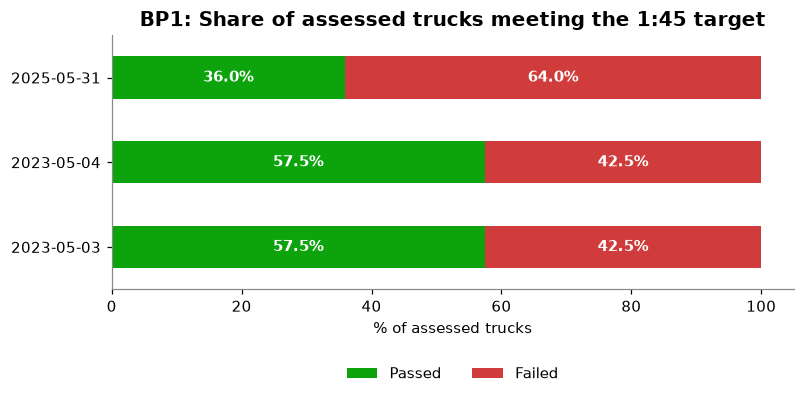

In [23]:
# 100% stacked bar: share of assessed trucks that passed / failed each day
share = pd.crosstab(assessed["DATE"], assessed["RESULT"], normalize="index").mul(100)[["Passed", "Failed"]]
ax = share.plot(kind="barh", stacked=True, color=[GREEN, RED], figsize=(8, 3),
                title="BP1: Share of assessed trucks meeting the 1:45 target")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontweight="bold")
ax.set_xlabel("% of assessed trucks"); ax.set_ylabel(""); ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
plt.savefig("../images/03_bp1_pass_rate.png", bbox_inches="tight"); plt.show()

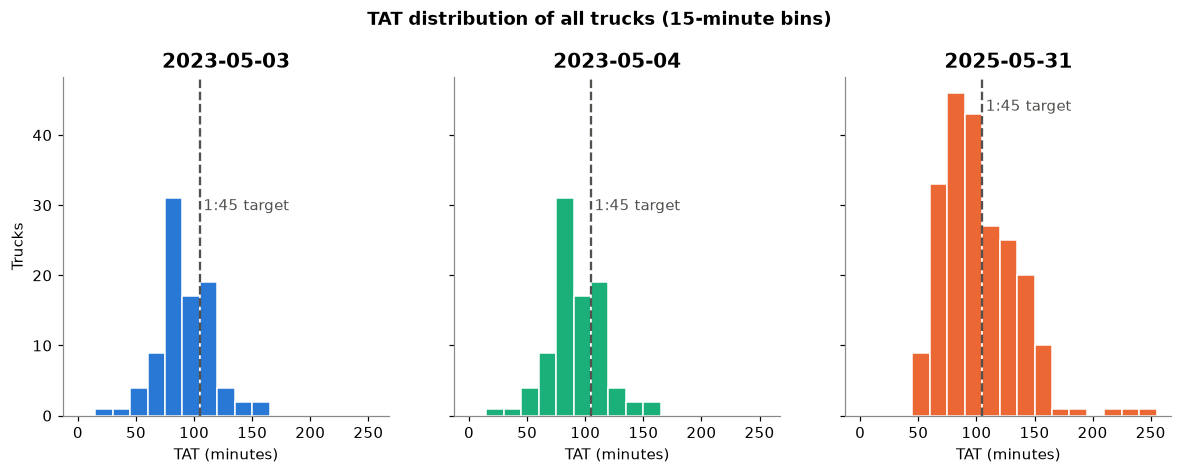

In [24]:
# Distribution of TAT for every truck, one panel per day, with the 1:45 target
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, day, colour in zip(axes, ["2023-05-03", "2023-05-04", "2025-05-31"], DAY_COLOURS):
    df[df["DATE"] == day]["TAT_MIN"].plot(kind="hist", bins=range(0, 270, 15), ax=ax, color=colour, edgecolor="white")
    ax.axvline(105, color=TARGET, linestyle="--"); ax.text(108, ax.get_ylim()[1] * 0.9, "1:45 target", color=TARGET)
    ax.set_title(day); ax.set_xlabel("TAT (minutes)"); ax.set_ylabel("Trucks")
fig.suptitle("TAT distribution of all trucks (15-minute bins)", fontweight="bold", y=1.03)
plt.savefig("../images/04_tat_distribution.png", bbox_inches="tight"); plt.show()

**Finding:** Only **36.0%** of assessed trucks (41 of 114) met the 1:45 target on 31 May 2025, against **57.5%** (23 of 40) on each of 3 and 4 May 2023. The average TAT of assessed trucks rose from 101.8 minutes on each 2023 day to 119.2 minutes in 2025 (1:42 to 1:59). Across all trucks it rose from 92.5 to 102.2 minutes. The 2025 day also handled 2.4 times as many trucks as a 2023 day (218 against 90). There are only three days, and the two 2023 logs are identical, so treat this as a signal, not a proven trend.

**Recommendation:** Track the pass rate every day, with a rolling 2-week trend, instead of one-off daily sheets. Collect at least a month of daily logs before setting improvement targets.

### BP2 – KPI coverage: trucks not assessed

In [25]:
# How many trucks fall outside the KPI (under 45,000 L)?
print(pd.crosstab(df["DATE"], df["RESULT"], margins=True))

# Average TAT and loading speed by truck size
df.groupby(["DATE", "SIZE_GROUP"], observed=True)[["TAT_MIN", "LITRES_PER_MIN"]].mean().round(1)

RESULT      Failed  Not assessed  Passed  All
DATE                                         
2023-05-03      17            50      23   90
2023-05-04      17            50      23   90
2025-05-31      73           104      41  218
All            107           204      87  398


TAT_MIN  LITRES_PER_MIN
DATE       SIZE_GROUP                                 
2023-05-03 Small (<=20k L)        74.6           197.8
           Medium (20k-45k L)     90.0           382.6
           Large (>=45k L)       101.8           527.9
2023-05-04 Small (<=20k L)        74.6           197.8
           Medium (20k-45k L)     90.0           382.6
           Large (>=45k L)       101.8           527.9
2025-05-31 Small (<=20k L)        81.1           181.9
           Medium (20k-45k L)     89.4           339.2
           Large (>=45k L)       119.2           481.8

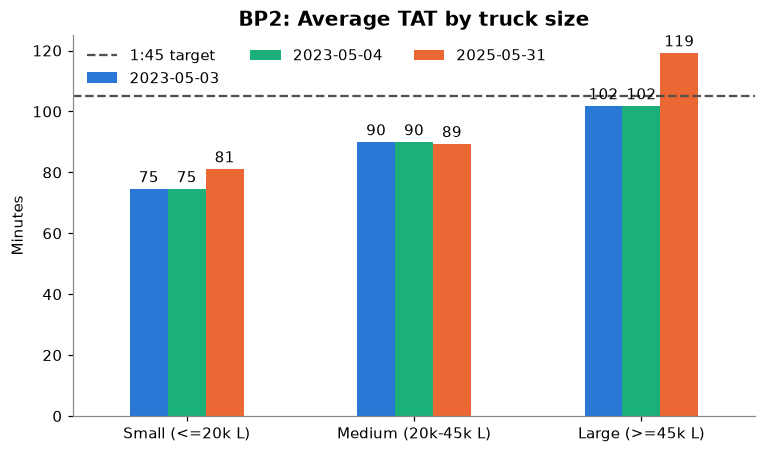

In [26]:
size_tat = df.groupby(["SIZE_GROUP", "DATE"], observed=True)["TAT_MIN"].mean().unstack()
ax = size_tat.plot(kind="bar", color=DAY_COLOURS, title="BP2: Average TAT by truck size")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2)
ax.axhline(105, color=TARGET, linestyle="--", label="1:45 target")
ax.set_ylabel("Minutes"); ax.set_xlabel(""); plt.xticks(rotation=0); ax.legend(ncol=3, loc="upper left")
plt.savefig("../images/05_bp2_tat_by_size.png", bbox_inches="tight"); plt.show()

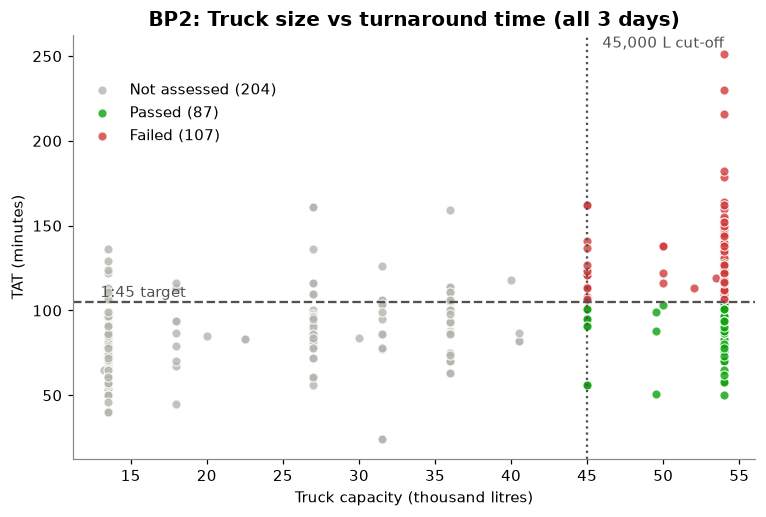

In [27]:
# Every truck: size against TAT, coloured by result. Small trucks are never assessed.
fig, ax = plt.subplots(figsize=(8, 5))
for result, colour in [("Not assessed", GREY), ("Passed", GREEN), ("Failed", RED)]:
    part = df[df["RESULT"] == result]
    ax.scatter(part["CAPACITY"] / 1000, part["TAT_MIN"], color=colour, label=f"{result} ({len(part)})",
               s=36, alpha=0.8, edgecolor="white", linewidth=0.8)
ax.axhline(105, color=TARGET, linestyle="--"); ax.axvline(45, color=TARGET, linestyle=":")
ax.text(46, 255, "45,000 L cut-off", color=TARGET); ax.text(13, 108, "1:45 target", color=TARGET)
ax.set_xlabel("Truck capacity (thousand litres)"); ax.set_ylabel("TAT (minutes)")
ax.set_title("BP2: Truck size vs turnaround time (all 3 days)"); ax.legend(loc="upper left", bbox_to_anchor=(0, 0.92))
plt.savefig("../images/06_bp2_capacity_vs_tat.png", bbox_inches="tight"); plt.show()

**Finding:** Just over half of all trucks (**204 of 398**) are labelled "No Remarks" because they hold under 45,000 L, so they are never measured. They are not quick to load: small trucks (20,000 L or less) average 75 minutes on site on each 2023 day and 81 minutes in 2025. They load at about 182 to 198 L/min, against 482 to 528 L/min for large trucks. Per litre loaded, they hold a bay about 2.7 times as long.

**Recommendation:** Give smaller trucks their own target scaled to size (for example, a target in L/min), so every truck is measured. Report KPI coverage (% of trucks assessed) next to the pass rate.

### BP3 – How late are late trucks? (15-minute bands)

In [28]:
# Number of trucks in each 15-minute band, per day (all trucks)
bp3 = pd.crosstab(df["TAT_BAND"], df["DATE"])
bp3 = bp3.loc[sorted(bp3.index, key=lambda s: int(s.split(")")[0]))]   # keep the bands in order
print(bp3)

# For failed trucks: average and maximum minutes over target
print(assessed[assessed["RESULT"] == "Failed"].groupby("DATE")["MINUTES_OVER_TARGET"].agg(["count", "mean", "max"]).round(1))

DATE          2023-05-03  2023-05-04  2025-05-31
TAT_BAND                                        
1) <1:00               6           6           9
2) 1:00-1:15           9           9          33
3) 1:15-1:30          31          31          46
4) 1:30-1:45          17          17          43
5) 1:45-2:00          19          19          27
6) 2:00-2:15           4           4          25
7) 2:15-2:30           2           2          20
8) 2:30-2:45           2           2          10
9) 2:45-3:00           0           0           1
10) 3:00+              0           0           4
            count  mean    max
DATE                          
2023-05-03     17  16.1   57.0
2023-05-04     17  16.1   57.0
2025-05-31     73  31.1  146.0


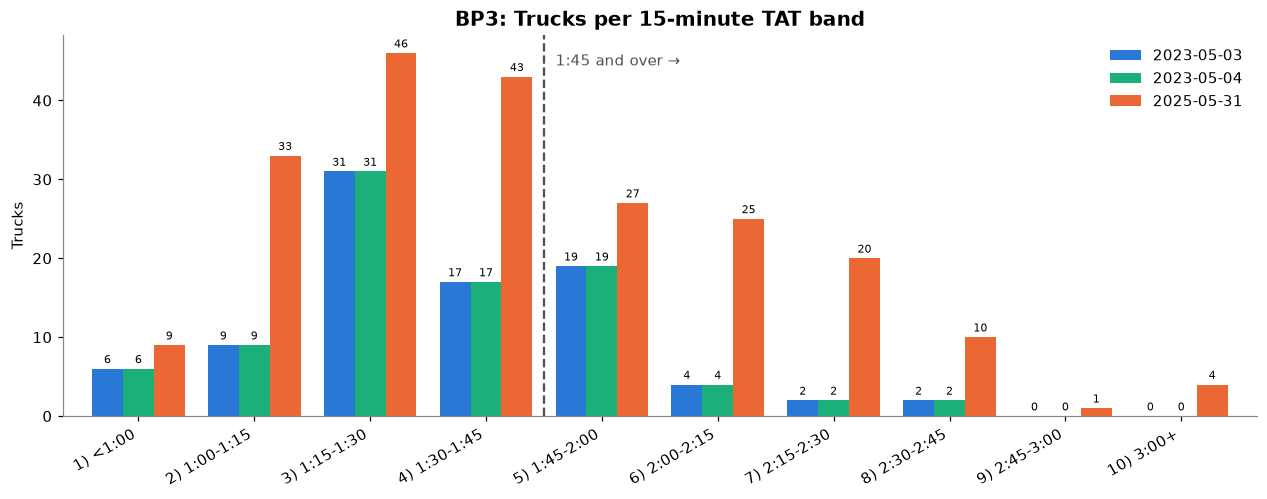

In [29]:
ax = bp3.plot(kind="bar", color=DAY_COLOURS, figsize=(14, 4.5), width=0.8, title="BP3: Trucks per 15-minute TAT band")
for container in ax.containers:
    ax.bar_label(container, padding=2, fontsize=7)
ax.axvline(3.5, color=TARGET, linestyle="--"); ax.text(3.6, ax.get_ylim()[1] * 0.92, "1:45 and over →", color=TARGET)
ax.legend(title=None)
ax.set_ylabel("Trucks"); ax.set_xlabel(""); plt.xticks(rotation=30, ha="right")
plt.savefig("../images/07_bp3_tat_bands.png", bbox_inches="tight"); plt.show()

**Finding:** In 2025, **60 of 218 trucks (27.5%)** took longer than 2 hours, against 8 of 90 (8.9%) on each 2023 day. Failed trucks averaged **31.1 minutes over target** in 2025 (worst case 146 minutes over, a 4:11 TAT), against 16.1 minutes on each 2023 day (worst 57 minutes over). Most trucks land in the 1:15 to 1:45 bands, but 2025 has a long tail past 2:00.

**Recommendation:** Escalate any truck still on site at 2:00 to the shift supervisor so the long tail gets attention. Measure the tail (% of trucks over 2:00) as a second KPI.

### BP4 – Product: diesel (AGO) vs petrol (PMS)

In [30]:
# Fail rate and average TAT by product for assessed trucks
bp4 = assessed.groupby(["DATE", "PRODUCT"]).agg(trucks=("TAT_MIN", "count"), avg_tat=("TAT_MIN", "mean"),
                                               failed=("RESULT", lambda s: (s == "Failed").sum()))
bp4["fail_rate_%"] = (bp4["failed"] / bp4["trucks"] * 100).round(1)
bp4.round(1)

trucks  avg_tat  failed  fail_rate_%
DATE       PRODUCT                                      
2023-05-03 AGO          18     95.8       5         27.8
           PMS          22    106.7      12         54.5
2023-05-04 AGO          18     95.8       5         27.8
           PMS          22    106.7      12         54.5
2025-05-31 AGO          68    118.6      46         67.6
           PMS          46    120.0      27         58.7

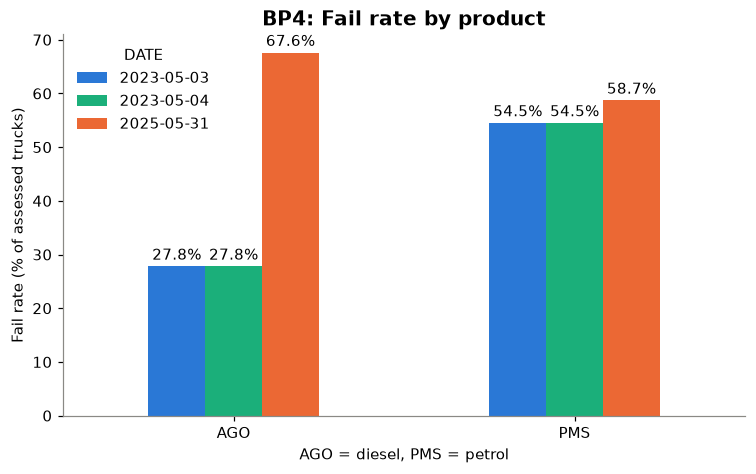

In [31]:
ax = bp4["fail_rate_%"].unstack(0).plot(kind="bar", color=DAY_COLOURS, title="BP4: Fail rate by product")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2)
ax.set_ylabel("Fail rate (% of assessed trucks)"); ax.set_xlabel("AGO = diesel, PMS = petrol"); plt.xticks(rotation=0)
plt.savefig("../images/08_bp4_product_fail_rate.png", bbox_inches="tight"); plt.show()

**Finding:** Diesel (AGO) got much worse. Its fail rate went from **27.8%** (5 of 18 on each 2023 day) to **67.6%** (46 of 68) in 2025. Petrol (PMS) went from 54.5% (12 of 22 each day) to 58.7% (27 of 46). In 2025, 68 of the 114 assessed trucks were diesel, which is where the volume and the failures grew.

**Recommendation:** Report the pass rate separately for each product gantry. Review diesel gantry capacity (bays, meters and dipping) against the larger 2025 diesel volume.

### BP5 – Customer channel: BOST vs OMC

In [32]:
bp5 = assessed.groupby(["DATE", "BOST/ OMC", "PRODUCT"]).agg(trucks=("TAT_MIN", "count"), avg_tat=("TAT_MIN", "mean"),
                                                            failed=("RESULT", lambda s: (s == "Failed").sum()))
bp5["fail_rate_%"] = (bp5["failed"] / bp5["trucks"] * 100).round(1)
bp5.round(1)

trucks  avg_tat  failed  fail_rate_%
DATE       BOST/ OMC PRODUCT                                      
2023-05-03 BOST      AGO           3     87.0       0          0.0
           OMC       AGO          15     97.6       5         33.3
                     PMS          22    106.7      12         54.5
2023-05-04 BOST      AGO           3     87.0       0          0.0
           OMC       AGO          15     97.6       5         33.3
                     PMS          22    106.7      12         54.5
2025-05-31 BOST      AGO          54    115.4      35         64.8
                     PMS          17    141.0      14         82.4
           OMC       AGO          14    131.0      11         78.6
                     PMS          29    107.7      13         44.8

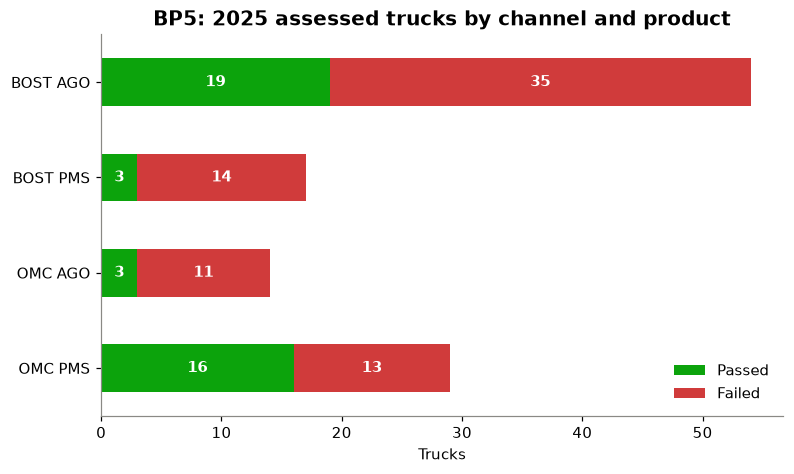

In [33]:
day25 = assessed[assessed["DATE"] == "2025-05-31"]
counts = pd.crosstab([day25["BOST/ OMC"], day25["PRODUCT"]], day25["RESULT"])[["Passed", "Failed"]]
counts.index = [f"{a} {b}" for a, b in counts.index]
ax = counts.plot(kind="barh", stacked=True, color=[GREEN, RED], title="BP5: 2025 assessed trucks by channel and product")
for container in ax.containers:
    ax.bar_label(container, label_type="center", color="white", fontweight="bold")
ax.invert_yaxis(); ax.set_xlabel("Trucks"); ax.legend(title=None)
plt.savefig("../images/09_bp5_channel_product_2025.png", bbox_inches="tight"); plt.show()

**Finding:** In 2025, BOST loads were 71 of 114 assessed trucks, against 3 of 40 on each 2023 day. BOST petrol was the worst group: **82.4% failed** (14 of 17), averaging 141 minutes. OMC diesel failed 78.6% (11 of 14) and BOST diesel 64.8% (35 of 54). OMC petrol did best, with 44.8% failed (13 of 29).

**Recommendation:** Agree loading windows (appointment slots) with BOST, so their bulk programme is spread across the day instead of arriving as one wave. Plan BOST petrol loads around single-arm capacity.

### BP6 – BDC performance

In [34]:
# Only BDCs with at least 5 assessed trucks, so the percentages mean something
bp6 = assessed.groupby("BDC").agg(trucks=("TAT_MIN", "count"), avg_tat=("TAT_MIN", "mean"),
                                  failed=("RESULT", lambda s: (s == "Failed").sum()))
bp6["fail_rate_%"] = (bp6["failed"] / bp6["trucks"] * 100).round(1)
bp6 = bp6[bp6["trucks"] >= 5].sort_values("fail_rate_%", ascending=False)
bp6.round(1)

,trucks,avg_tat,failed,fail_rate_%
BDC,,,,
VIHAMA ENERGY LIMITED,5,160.0,5,100.0
EAGLE PETROLEUM,5,164.8,5,100.0
INTERNATIONAL PETROLEUM RESOURCES GH,10,133.3,7,70.0
GOENERGY,32,111.4,22,68.8
BOST (G4O),63,112.3,37,58.7
OIL CHANNEL,19,109.4,11,57.9
ASTRA OIL,10,108.2,5,50.0
EVERSTONE ENERGY LIMITED,17,107.4,8,47.1
GENYSIS GLOBAL LIMITED,12,85.0,0,0.0


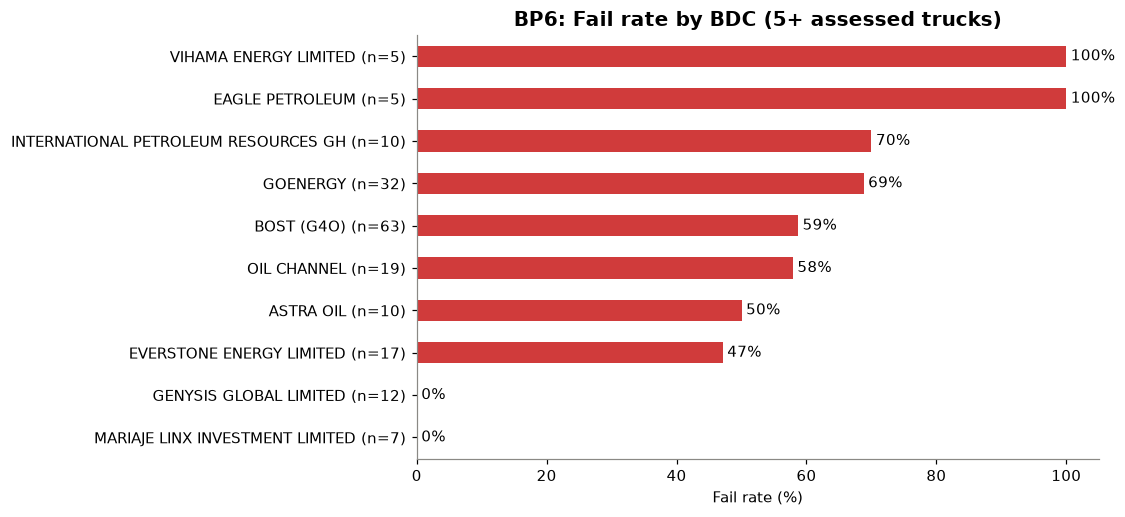

In [35]:
labels = [f"{name} (n={n})" for name, n in zip(bp6.index, bp6["trucks"])]
ax = bp6["fail_rate_%"].plot(kind="barh", color=RED, figsize=(8, 5), title="BP6: Fail rate by BDC (5+ assessed trucks)")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3); ax.invert_yaxis()
ax.set_xlabel("Fail rate (%)"); ax.set_ylabel(""); ax.grid(False)
plt.savefig("../images/10_bp6_bdc_fail_rate.png", bbox_inches="tight"); plt.show()

**Finding:** Among BDCs with at least 5 assessed trucks over the three days, **Eagle Petroleum and Vihama Energy failed 5 of 5 each**, averaging 165 and 160 minutes. All 10 were BOST petrol loads in 2025. International Petroleum Resources failed 7 of 10 (70%). The largest BDC, BOST (G4O), failed 37 of 63 (58.7%). Genysis Global (12 trucks) and Mariaje Linx (7 trucks) had no failures.

**Recommendation:** Send each BDC a monthly scorecard with pass rate and average TAT. Review product-release and paperwork steps for the worst BDCs, and compare them with Genysis and Mariaje Linx loads, which ran smoothly.

### BP7 – Hauliers (BOST loads) and OMC customers: repeat late trucks

In [36]:
# Hauliers with 2 or more failed BOST loads
late = assessed[assessed["RESULT"] == "Failed"]
print(late["HAULIER"].value_counts().head(8))

# OMC customers with the most failed loads
print(late["OMC_CUSTOMER"].value_counts().head(8))

HAULIER
A-BEK         2
OIL FAST      2
ROCOMENS      2
J.K HORGLE    2
LE FORTS      2
KTC           2
J.K NARH      2
SADICK        1
Name: count, dtype: int64
OMC_CUSTOMER
GOIL                           22
ALLIED OIL COMPANY LIMITED     11
ZEN PETROLEUM                   5
WEST PORT PETROLEUM LIMITED     5
PACIFIC OIL                     2
STAR OIL CO. LTD                2
NICK PETROLEUM                  2
FAMOUS ENERGY LIMITED           2
Name: count, dtype: int64


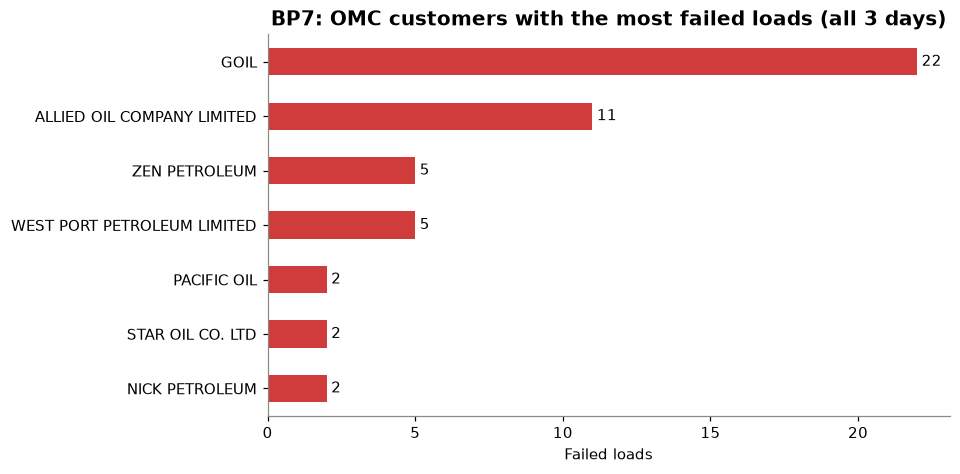

In [37]:
top_omc = late["OMC_CUSTOMER"].value_counts().head(7)
ax = top_omc.plot(kind="barh", color=RED, title="BP7: OMC customers with the most failed loads (all 3 days)")
ax.bar_label(ax.containers[0], padding=3); ax.invert_yaxis(); ax.set_xlabel("Failed loads"); ax.set_ylabel(""); ax.grid(False)
plt.savefig("../images/11_bp7_omc_failed.png", bbox_inches="tight"); plt.show()

**Finding:** No BOST haulier failed more than twice: 7 hauliers had 2 failures each. Lateness is spread across many hauliers, which points to depot-side delays rather than bad driver behaviour. On the OMC side, **GOIL had 22 failed loads** (11 of 16 on each 2023 day), Allied Oil 11, and West Port Petroleum 5 (all 5 of its assessed trucks in 2025).

**Recommendation:** Focus improvement on depot processes, not on penalising hauliers. Review GOIL's and West Port's loading programmes (order timing and documents) with them.

### BP8 – Time of arrival and congestion (2025)

In [38]:
day25_all = df[df["DATE"] == "2025-05-31"]
bp8 = day25_all.groupby("ARRIVAL_HOUR").agg(trucks=("TAT_MIN", "count"), avg_tat=("TAT_MIN", "mean")).round(1)
print(bp8)

# Fail rate of assessed trucks arriving before 09:00 vs from 09:00
early = day25["IN_MIN"] < 9 * 60
print("Fail rate before 09:00:", round((day25[early]["RESULT"] == "Failed").mean() * 100, 1), "%  trucks:", early.sum())
print("Fail rate from 09:00:  ", round((day25[~early]["RESULT"] == "Failed").mean() * 100, 1), "%  trucks:", (~early).sum())

              trucks  avg_tat
ARRIVAL_HOUR                 
5                  5    135.6
6                 12    121.2
7                 10    125.9
8                 18    130.2
9                 11     88.4
10                16     97.2
11                17     92.4
12                16     90.6
13                20     98.2
14                19    113.2
15                18     99.4
16                19    106.7
17                16     97.2
18                10     76.9
19                10     67.5
20                 1     70.0
Fail rate before 09:00: 73.8 %  trucks: 42
Fail rate from 09:00:   58.3 %  trucks: 72


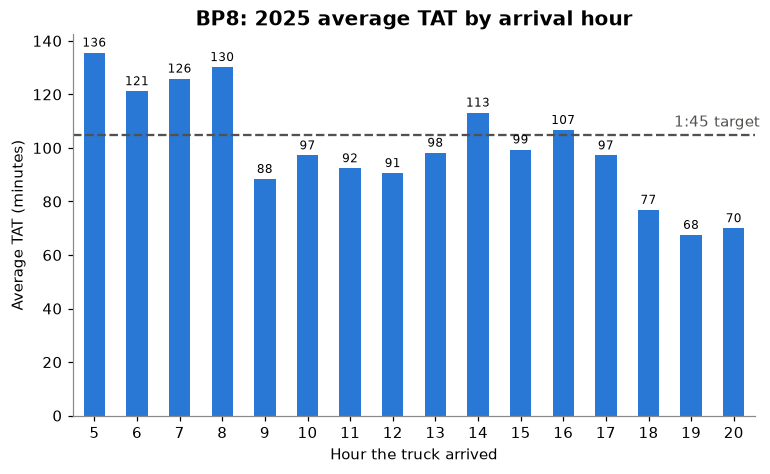

In [39]:
ax = bp8["avg_tat"].plot(kind="bar", color=BLUE, title="BP8: 2025 average TAT by arrival hour")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=2, fontsize=8)
ax.axhline(105, color=TARGET, linestyle="--"); ax.text(13.6, 108, "1:45 target", color=TARGET)
ax.set_xlabel("Hour the truck arrived"); ax.set_ylabel("Average TAT (minutes)"); plt.xticks(rotation=0)
plt.savefig("../images/12_bp8_tat_by_arrival_hour.png", bbox_inches="tight"); plt.show()

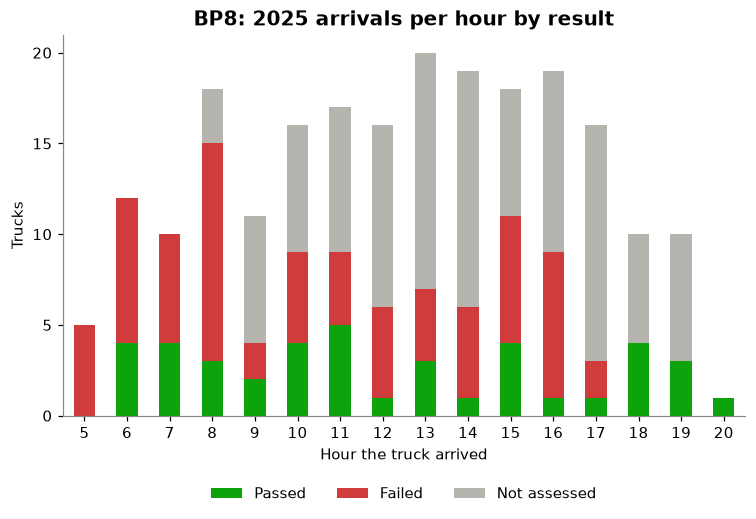

In [40]:
# How many trucks arrived each hour in 2025, split by result
arrivals = pd.crosstab(day25_all["ARRIVAL_HOUR"], day25_all["RESULT"])[["Passed", "Failed", "Not assessed"]]
ax = arrivals.plot(kind="bar", stacked=True, color=[GREEN, RED, GREY], title="BP8: 2025 arrivals per hour by result")
ax.set_xlabel("Hour the truck arrived"); ax.set_ylabel("Trucks"); plt.xticks(rotation=0)
ax.yaxis.get_major_locator().set_params(integer=True)   # whole trucks only
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.savefig("../images/13_bp8_arrivals_by_result.png", bbox_inches="tight"); plt.show()

**Finding:** On 31 May 2025, trucks arriving between 05:00 and 08:59 averaged **127 minutes** (45 trucks, 41 of them BOST), against 96 minutes for later arrivals and 72 minutes after 18:00. The assessed fail rate was **73.8%** for trucks that arrived before 09:00 (42 trucks), against 58.3% from 09:00 (72 trucks).

**Recommendation:** Spread arrivals: stagger the BOST morning wave, open more bays and staff the documentation desk fully from 05:00, and move flexible OMC loads into the quieter evening window.

### BP9 – Root causes: the Challenge Register

In [41]:
# Count CR codes on failed trucks
print(late.groupby(["DATE", "CR_DESC"]).size())

# Cross-check against product: is the code just following the product?
pd.crosstab(late["CR_DESC"], [late["DATE"], late["PRODUCT"]])

DATE        CR_DESC                             
2023-05-03  NTL (Internet) Delay                     5
            Single Loading Arm Delay                12
2023-05-04  NTL (Internet) Delay                     5
            Single Loading Arm Delay                12
2025-05-31  Dipping Platform/Documentation Delay    46
            Not recorded                             1
            Rock Africa Internet/Seal Delay          1
            Single Loading Arm Delay                25
dtype: int64


DATE                                 2023-05-03     2023-05-04     2025-05-31    
PRODUCT                                     AGO PMS        AGO PMS        AGO PMS
CR_DESC                                                                          
Dipping Platform/Documentation Delay          0   0          0   0         46   0
NTL (Internet) Delay                          5   0          5   0          0   0
Not recorded                                  0   0          0   0          0   1
Rock Africa Internet/Seal Delay               0   0          0   0          0   1
Single Loading Arm Delay                      0  12          0  12          0  25

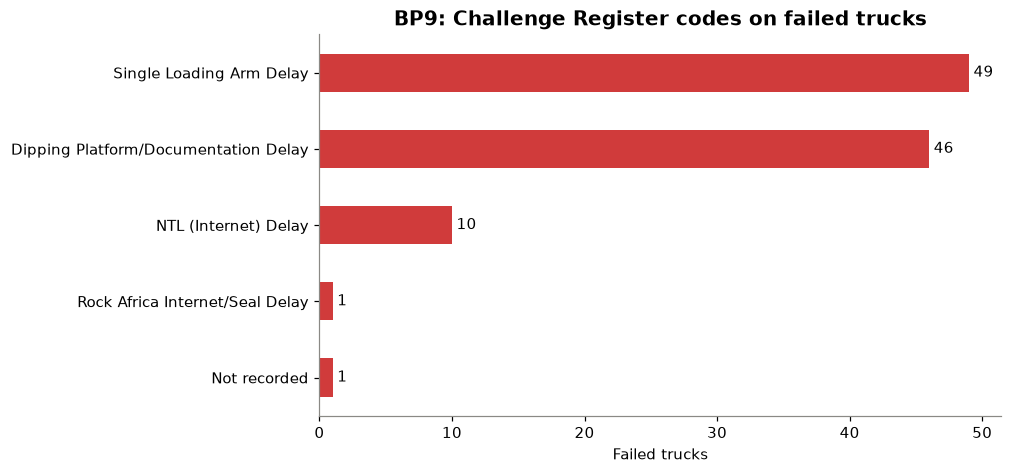

In [42]:
causes = late["CR_DESC"].value_counts()
ax = causes.plot(kind="barh", color=RED, title="BP9: Challenge Register codes on failed trucks")
ax.bar_label(ax.containers[0], padding=3); ax.invert_yaxis(); ax.set_xlabel("Failed trucks"); ax.set_ylabel(""); ax.grid(False)
plt.savefig("../images/14_bp9_challenge_register.png", bbox_inches="tight"); plt.show()

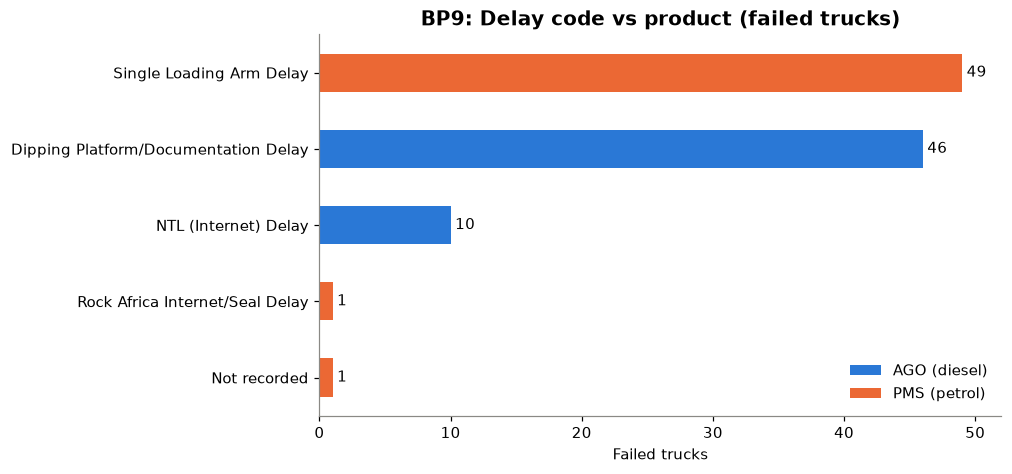

In [43]:
# Each cause split by product: every cause belongs to one product only
by_product = pd.crosstab(late["CR_DESC"], late["PRODUCT"]).loc[causes.index]
ax = by_product.plot(kind="barh", stacked=True, color=[BLUE, ORANGE], title="BP9: Delay code vs product (failed trucks)")
for container in ax.containers:
    ax.bar_label(container, labels=[int(v) if v > 0 else "" for v in container.datavalues], padding=3)
ax.invert_yaxis(); ax.set_xlabel("Failed trucks"); ax.set_ylabel(""); ax.set_xlim(0, 52)
ax.legend(["AGO (diesel)", "PMS (petrol)"])
plt.savefig("../images/15_bp9_cause_vs_product.png", bbox_inches="tight"); plt.show()

**Finding:** Two codes explain almost all 107 failures. **Single Loading Arm Delay** covers 49 (45.8%), and every one is a petrol truck. **Dipping Platform/Documentation Delay** covers 46 (43.0%), and every one is a 2025 diesel truck. The remaining codes are NTL internet delay (10, all 2023 diesel), Rock Africa internet/seal delay (1) and one truck not recorded. Because the code follows the product exactly, it is probably assigned per product line rather than investigated per truck.

**Recommendation:** Treat these as two bottleneck projects: add or restore a second petrol loading arm, and time-study the dipping platform and documentation steps for diesel. Fix the register itself: make the CR mandatory for every failed truck (data validation) and record time stamps per stage (gate in, start of loading, end of loading, documents, gate out) so each cause is backed by evidence.

### BP10 – Cost of delay

In [44]:
# Minutes above the 1:45 target, summed over failed trucks
bp10 = late.groupby("DATE")["MINUTES_OVER_TARGET"].agg(["count", "sum", "mean"])
bp10["truck_hours_lost"] = (bp10["sum"] / 60).round(2)
bp10["extra_loads_at_target"] = (bp10["sum"] / 105).round(1)   # how many more 1:45 loads that time could cover
bp10.round(1)

,count,sum,mean,truck_hours_lost,extra_loads_at_target
DATE,,,,,
2023-05-03,17,274.0,16.1,4.6,2.6
2023-05-04,17,274.0,16.1,4.6,2.6
2025-05-31,73,2271.0,31.1,37.8,21.6


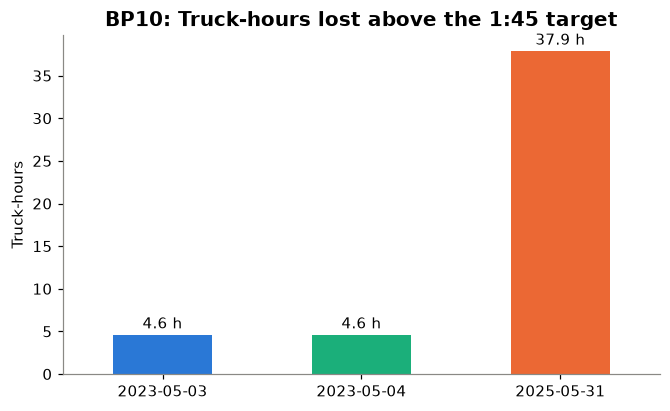

In [45]:
ax = bp10["truck_hours_lost"].plot(kind="bar", color=DAY_COLOURS, figsize=(7, 4), title="BP10: Truck-hours lost above the 1:45 target")
ax.bar_label(ax.containers[0], fmt="%.1f h", padding=2)
ax.set_ylabel("Truck-hours"); ax.set_xlabel(""); plt.xticks(rotation=0)
plt.savefig("../images/16_bp10_truck_hours_lost.png", bbox_inches="tight"); plt.show()

**Finding:** On 31 May 2025, the 73 failed trucks spent **2,271 minutes (37.9 truck-hours)** beyond the 1:45 target. That time could have covered about **21.6 extra loads** at the standard TAT. On each 2023 day, the figure was 274 minutes (4.6 truck-hours).

**Recommendation:** Put a money value on this using the depot's cost per truck-hour or demurrage rate, which is not in the data. Halving the excess time would free about 19 truck-hours on a day like 31 May 2025.

### Summary card

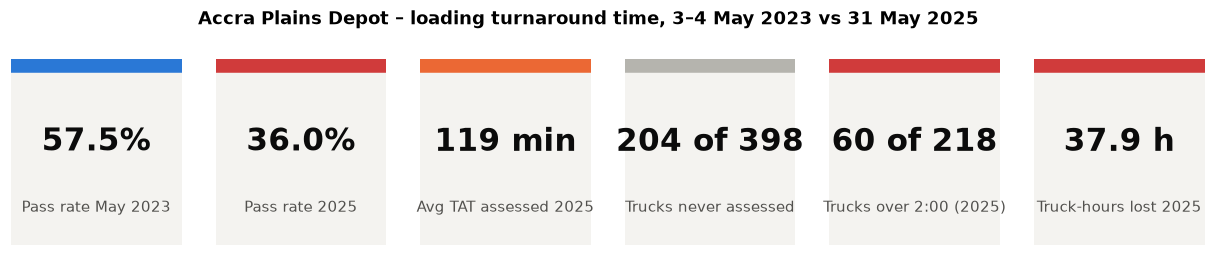

In [46]:
# One image with the headline numbers, for the top of the README
pass23 = bp1.loc["2023-05-03", "Pass rate %"]   # 3 and 4 May 2023 have the same rate
pass25 = bp1.loc["2025-05-31", "Pass rate %"]
tiles = [
    ("Pass rate May 2023", f"{pass23:.1f}%", BLUE),
    ("Pass rate 2025", f"{pass25:.1f}%", RED),
    ("Avg TAT assessed 2025", f"{assessed[assessed['DATE'] == '2025-05-31']['TAT_MIN'].mean():.0f} min", ORANGE),
    ("Trucks never assessed", f"{(df['RESULT'] == 'Not assessed').sum()} of {len(df)}", GREY),
    ("Trucks over 2:00 (2025)", f"{(day25_all['TAT_MIN'] > 120).sum()} of {len(day25_all)}", RED),
    ("Truck-hours lost 2025", f"{bp10.loc['2025-05-31', 'sum'] / 60:.1f} h", RED),
]
fig, axes = plt.subplots(1, 6, figsize=(14, 2.2))
for ax, (label, value, colour) in zip(axes, tiles):
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, color="#f4f3f0", transform=ax.transAxes))
    ax.add_patch(plt.Rectangle((0, 0.93), 1, 0.07, color=colour, transform=ax.transAxes))
    ax.text(0.5, 0.55, value, ha="center", va="center", fontsize=20, fontweight="bold", color="#0b0b0b")
    ax.text(0.5, 0.2, label, ha="center", va="center", fontsize=10, color="#52514e")
fig.suptitle("Accra Plains Depot – loading turnaround time, 3–4 May 2023 vs 31 May 2025", fontweight="bold", y=1.08)
plt.savefig("../images/01_kpi_summary.png", bbox_inches="tight"); plt.show()

## 5. Summary
| # | Business problem | Key number |
|---|---|---|
| 1 | TAT compliance | Pass rate 57.5% (each 2023 day) → **36.0%** (2025) |
| 2 | KPI coverage | **204 of 398** trucks never assessed |
| 3 | Long tail | **60 of 218** trucks over 2:00 in 2025 |
| 4 | Product | Diesel fail rate 27.8% → **67.6%** |
| 5 | Channel | BOST petrol **82.4%** failed (2025) |
| 6 | BDC | Eagle Petroleum and Vihama Energy **5 of 5** failed |
| 7 | Hauliers | No haulier failed more than twice, so the delays are depot-side |
| 8 | Arrival time | Before 09:00: **127 min** average TAT, 73.8% failed |
| 9 | Root cause | Two codes = **89%** of failures, coded by product |
| 10 | Cost | **37.9 truck-hours** lost above target on 31 May 2025 |

**Main message:** the depot handled 2.4 times more trucks in 2025 than on a 2023 day, mostly a morning wave of BOST diesel and petrol loads. Two bottlenecks, the single petrol loading arm and the diesel dipping/documentation step, turned that volume into a 64% failure rate. Fix those two steps, spread arrivals across the day and measure every truck.